<a href="https://colab.research.google.com/github/Amartyaraja/ML-PROJECTS/blob/main/DecodeAIMLcode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# sales predictions(Regression) using ML




In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from scipy import stats



In [ ]:
# data loading ,and descriptive analysis
url="https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"
df=pd.read_csv(url,index_col=0)

In [ ]:
df.head()

,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [ ]:
# data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 7.8 KB


In [ ]:
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [ ]:
df.isnull().sum()

,0
TV,0
radio,0
newspaper,0
sales,0


### observations

1.all four colms are numeric and float64 so encoding not needed
2. no missing or null values
3. tv budget varies alot
4. sales also varying from 1.6 to 27 th unit




### EDA and visualisation

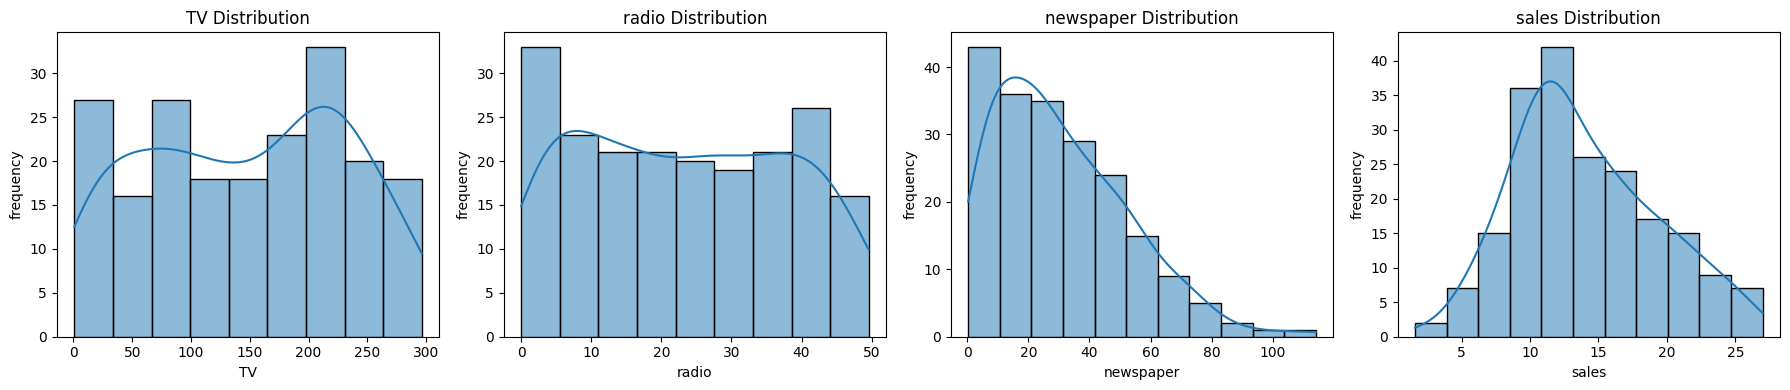

In [ ]:
# to check dist shape and outliers
fig,axes= plt.subplots(1,4,  figsize=(18,4))
for i,col in enumerate(df.columns):
  sns.histplot(df[col],kde=True,ax=axes[i])
  axes[i].set_title(f'{col} Distribution')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('frequency')
plt.tight_layout()
plt.show()


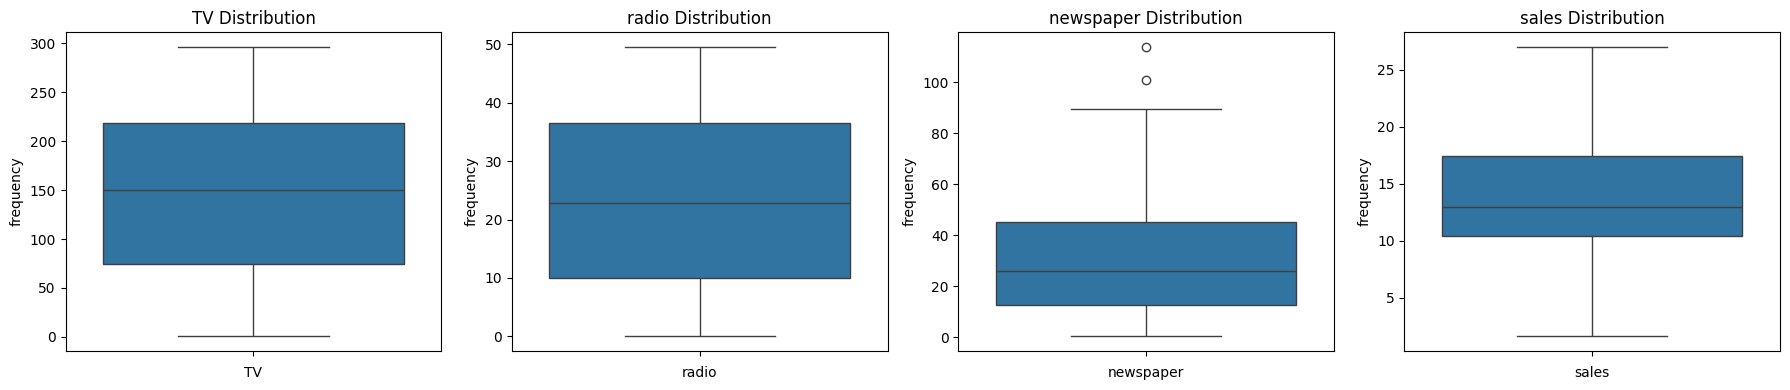

In [ ]:
#boxplot to check outliers and dist shape
fig,axes= plt.subplots(1,4,  figsize=(18,4))
for i,col in enumerate(df.columns):
  sns.boxplot(df[col],ax=axes[i])
  axes[i].set_title(f'{col} Distribution')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('frequency')
plt.tight_layout()
plt.show()


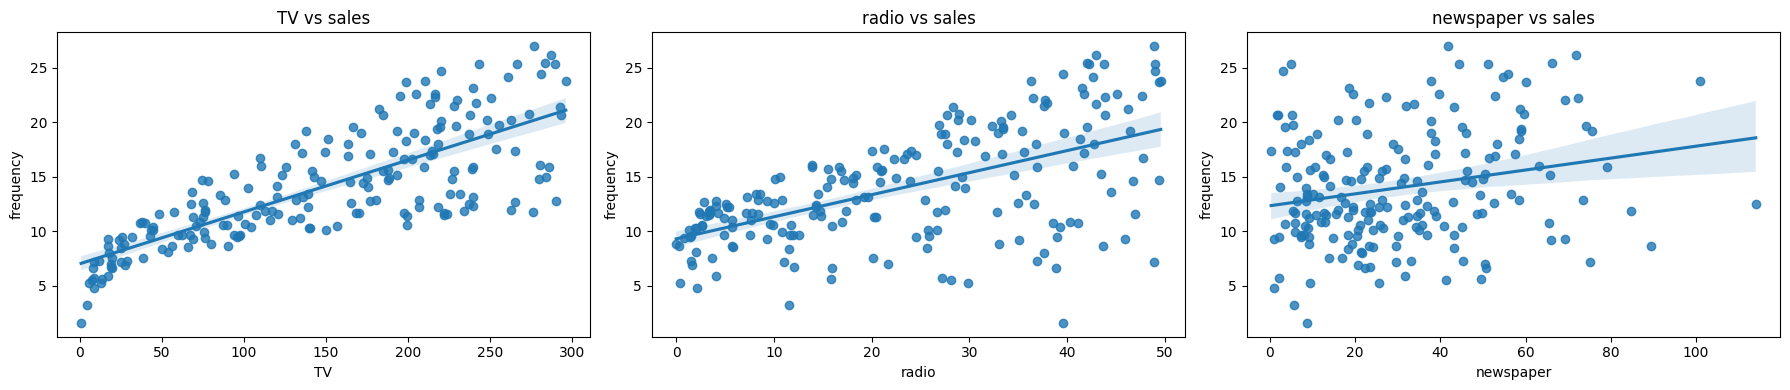

In [ ]:
# scatter plot with regression lines for each feature vs target
features=df.columns[:-1]
target=df.columns[-1]
fig,axes=plt.subplots(1,3,figsize=(18,4))
for i,feature in enumerate(features):
  sns.regplot(x=df[feature],y=df[target],ax=axes[i])
  axes[i].set_title(f'{feature} vs {target}')
  axes[i].set_xlabel(feature)
  axes[i].set_ylabel('frequency')
plt.tight_layout()
plt.show()

              TV  radio  newspaper  sales
TV         1.000  0.055      0.057  0.782
radio      0.055  1.000      0.354  0.576
newspaper  0.057  0.354      1.000  0.228
sales      0.782  0.576      0.228  1.000


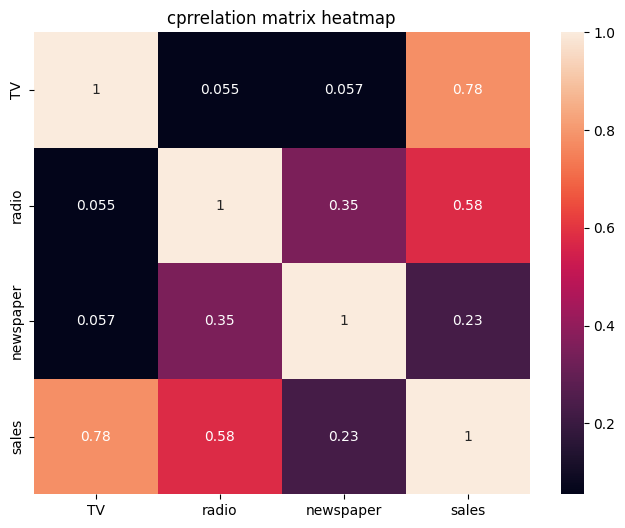

In [ ]:
corr=df.corr().round(3)
print(corr)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True)
plt.title("cprrelation matrix heatmap")
plt.show()

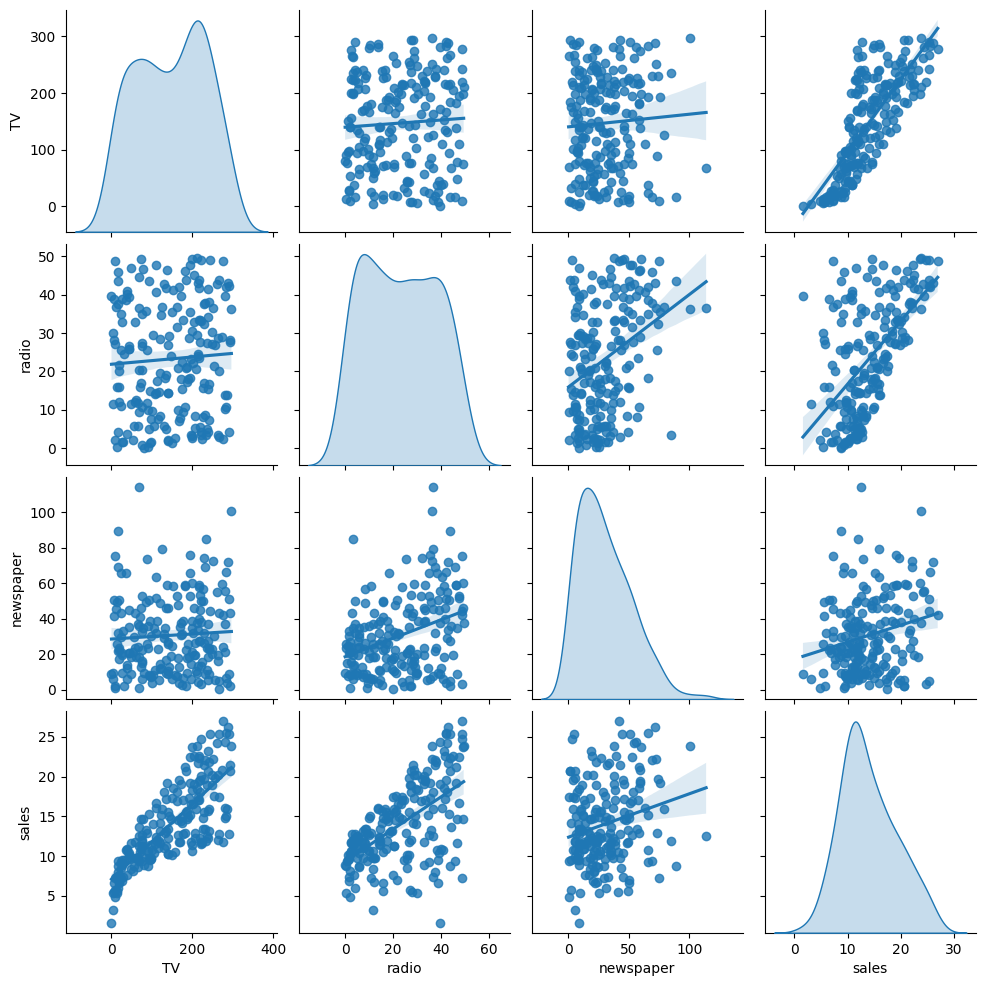

In [ ]:
 # pair plot
sns.pairplot(df,kind='reg',diag_kind='kde')

In [ ]:
# now we will biuild the model

X=df[['TV','radio','newspaper']]
y=df['sales']

In [ ]:
#split the data set in train test
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.3)

In [ ]:
X_train.shape

(140, 3)

In [ ]:
slr=LinearRegression()
slr.fit(X_train[['TV']],y_train)  # fitting slr model
y_pred=slr.predict(X_test[['TV']])

Text(0, 0.5, 'sales')

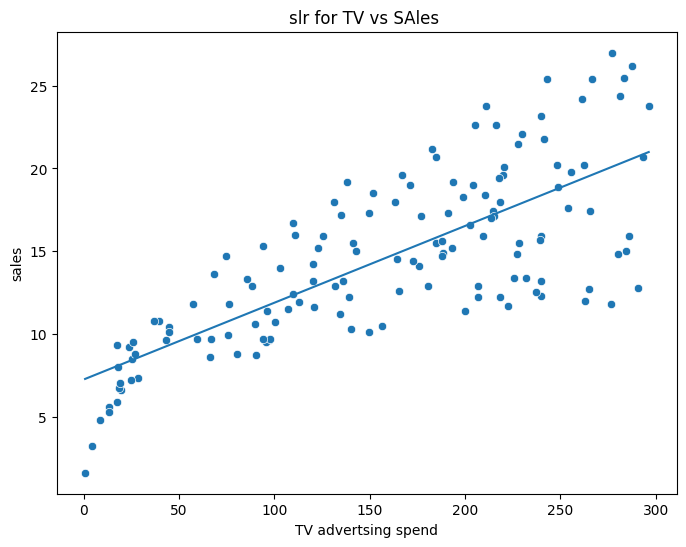

In [ ]:
#visualise the model

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_train['TV'],y=y_train)
sns.lineplot(x=X_train['TV'],y=slr.predict(X_train[["TV"]]))
plt.title("slr for TV vs SAles ")
plt.xlabel("TV advertsing spend")
plt.ylabel('sales')


In [ ]:
#evaluation

mse_slr=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
mae_slr=mean_absolute_error(y_test,y_pred)

print(mse_slr,r2,mae_slr)

8.970991242413614 0.6714477229302764 2.2758809050205113


In [ ]:
# sclaing the features for multiple linear regression

from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.fit_transform(X_test)


In [ ]:
# mlr model fitting


mlr=LinearRegression()
mlr.fit(X_train_scaled,y_train)
y_pred_mlr=mlr.predict(X_test_scaled)
print("intercept_ b0", mlr.intercept_)
for i, col in enumerate(X.columns):
  print(f'coefficient of {col} is (beta_{i+1}) : {mlr.coef_[i]}')


intercept_ b0 14.497142857142858
coefficient of TV is (beta_1) : 3.6833407810865872
coefficient of radio is (beta_2) : 2.9062524207719314
coefficient of newspaper is (beta_3) : 0.14194771902905545


In [ ]:
r2_mlr=r2_score(y_test,y_pred_mlr)
mse_mlr=mean_squared_error(y_test,y_pred_mlr)
mae_mlr=mean_absolute_error(y_test,y_pred_mlr)
print(mse_mlr,r2_mlr,mae_mlr)
print("RMSE is", np.sqrt(mse_mlr))

6.209703302450422 0.7725767303950064 1.7677050331419961
RMSE is 2.491927627851664


<Axes: xlabel='sales'>

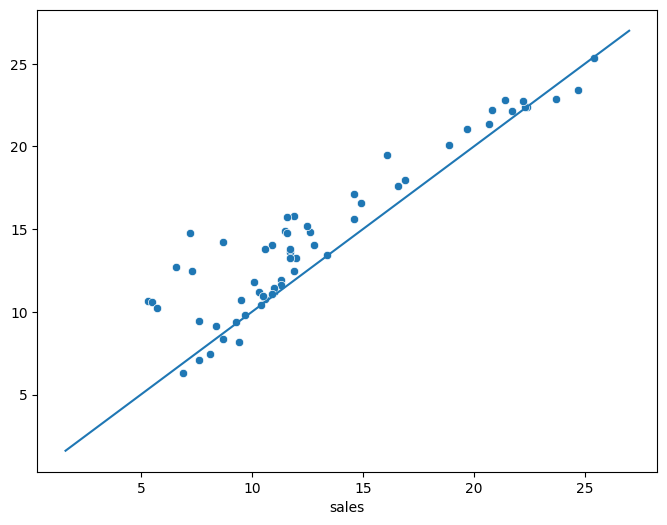

In [ ]:
# actual vs predicted sales

plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test,y=y_pred_mlr)
sns.lineplot(x=[y.min(),y.max()],y=[y.min(),y.max()])


Text(0, 0.5, 'coefficient values')

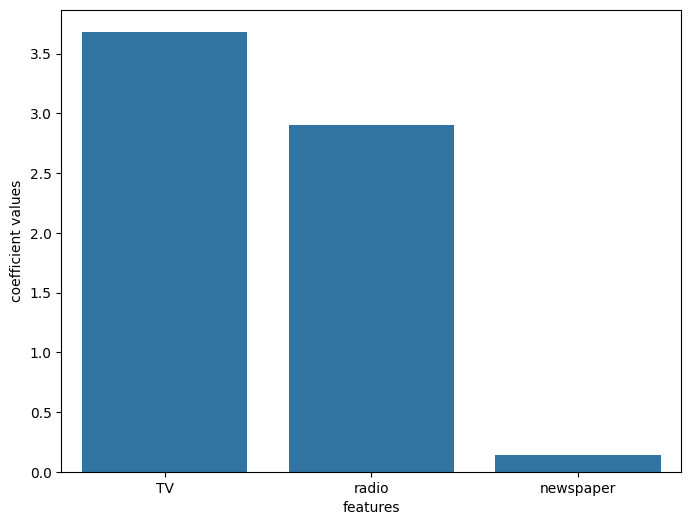

In [ ]:
# checking the beta values
plt.figure(figsize=(8,6))
sns.barplot(x=X.columns,y=mlr.coef_)
plt.xlabel("features")
plt.ylabel("coefficient values")


In [ ]:
# what this mean
# this means for every 1000 doller incresase on adv on tv sale increase bt 0.05 thousand unit




# now here we will scale the fetaure of mlr in above

# logistic regression project

In [ ]:
df=pd.read_csv("https://www.openml.org/data/get_csv/1595261/phpMawTba",na_values=["?"])
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [ ]:
df.shape

(48842, 15)

In [ ]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'class'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  class           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [ ]:
df.isna().sum() # not showing null because null is given by ?

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:

for col in df.columns:
  print(df[col].value_counts())

age
36    1348
35    1337
33    1335
23    1329
31    1325
      ... 
88       6
85       5
87       3
89       2
86       1
Name: count, Length: 74, dtype: int64
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64
fnlwgt
203488    21
190290    19
120277    19
125892    18
126569    18
          ..
436163     1
320084     1
125976     1
211349     1
120478     1
Name: count, Length: 28523, dtype: int64
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, d

In [ ]:
# workclasss occupation and native country has null value
